# 01 · Data overview

**Goal:** understand what data I have before I judge its quality. What is in each file, how much data each machine has, when the machines run, and what the faults look like.

**How to read this notebook.** Each section follows the same pattern:
1. A question in plain words.
2. Short code cells, each one doing one thing.
3. `Obs:` what I see. `Decision:` what I do with it. `Ask the operator:` what I would ask.

**The four files, like the papers of a car garage** (more in `docs/01 - Data.md`):

| File | Garage example | What it is |
|---|---|---|
| `ahu_metadata.csv` | ID card of each car | One row per machine: size, zone, sensors |
| `ahu_train.parquet` | Black box, Jan–Jun | Sensor readings every 5 minutes |
| `fault_labels_train.csv` | Repair reports | 28 confirmed faults: which machine, which fault, from when to when |
| `ahu_test.parquet` | Black box, Jul–Aug | Same readings, no reports. This is what I predict |

Next notebooks: `02_data_quality` (can I trust the data?), `03_patterns` (how does a healthy machine behave?), `04_faults` (do the faults show in the data?).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from ahu_fdd.config import FAULT_NAMES, FAULT_TYPES
from ahu_fdd.data import add_building, label_rows, load_labels, load_metadata, load_sensors
from ahu_fdd.eda import coverage_by_building, coverage_per_ahu, fan_on_hours_per_event
from ahu_fdd.plots import BUILDING_COLORS, FAULT_COLORS, save_fig, set_style

set_style()  # same look for every chart
pd.set_option("display.max_columns", 30)

In [2]:
# Load the four files. load_sensors() also sorts the diaries by machine and time
meta = load_metadata()  # ID cards
labels = load_labels()  # repair reports
train = add_building(load_sensors("train"))  # diary Jan-Jun, with a 'building' column
test = add_building(load_sensors("test"))  # diary Jul-Aug

## 1. The ID cards: what does each machine look like?

**How:** look at a few rows, then group by building to compare sizes and sensors.

In [3]:
meta.head()

,ahu_id,building,building_type,serves,design_airflow_m3h,fan_rated_kw,has_co2_sensor,has_airflow_station,operating_hours
0,B1-AHU-01,B1,office,meeting rooms,15000,10.1,True,False,Mon-Fri 07:00-19:30 except public holidays
1,B1-AHU-02,B1,office,office floors,26000,20.4,True,False,Mon-Fri 07:00-19:30 except public holidays
2,B1-AHU-03,B1,office,open plan,24000,20.9,True,False,Mon-Fri 07:00-19:30 except public holidays
3,B1-AHU-04,B1,office,open plan,21000,17.8,True,False,Mon-Fri 07:00-19:30 except public holidays
4,B1-AHU-05,B1,office,lobby,17000,10.2,True,False,Mon-Fri 07:00-19:30 except public holidays


In [4]:
# One row per building: number of machines, size range, and which extra sensors they have
meta.groupby(["building", "building_type"]).agg(
    ahus=("ahu_id", "size"),
    airflow_min=("design_airflow_m3h", "min"),
    airflow_max=("design_airflow_m3h", "max"),
    fan_kw_min=("fan_rated_kw", "min"),
    fan_kw_max=("fan_rated_kw", "max"),
    co2_sensor=("has_co2_sensor", "all"),
    airflow_sensor=("has_airflow_station", "all"),
)

,,ahus,airflow_min,airflow_max,fan_kw_min,fan_kw_max,co2_sensor,airflow_sensor
building,building_type,,,,,,,
B1,office,16,12500,30000,8.0,26.2,True,False
B2,hospital,12,6000,20000,4.3,15.7,True,True
B3,mall,12,25000,44500,17.1,36.9,False,False


In [5]:
# Which zones each building's machines serve
meta.groupby("building")["serves"].unique()

building
B1     [meeting rooms, office floors, open plan, lobby]
B2        [pharmacy, wards, clinics, outpatient, admin]
B3    [retail L2, cinema foyer, food court, retail L...
Name: serves, dtype: object

In [6]:
# Declared schedules. Most are the same per building, so I look for the exceptions
meta.groupby(["building", "operating_hours"])["ahu_id"].apply(list)

building  operating_hours                           
B1        24/7                                                                     [B1-AHU-15, B1-AHU-16]
          Mon-Fri 07:00-19:30 except public holidays    [B1-AHU-01, B1-AHU-02, B1-AHU-03, B1-AHU-04, B...
B2        24/7                                          [B2-AHU-01, B2-AHU-02, B2-AHU-03, B2-AHU-04, B...
B3        Daily 09:00-23:00                             [B3-AHU-01, B3-AHU-02, B3-AHU-03, B3-AHU-04, B...
Name: ahu_id, dtype: object

**Obs:**
- 40 machines: 16 in the office (B1), 12 in the hospital (B2), 12 in the mall (B3).
- The machines are very different in size. A mall machine moves up to 44,500 m³/h and a small hospital one 6,000 m³/h, about 7 times less. So I can't compare raw values like fan power or airflow between machines. I will compare each machine with itself, or normalise.
- Extra sensors depend on the building: CO2 in B1 and B2, airflow only in B2, nothing extra in B3. B3 is the building with fewer sensors.
- Each building has one declared schedule, except two B1 machines (B1-AHU-15 and B1-AHU-16) that run 24/7.

## 2. The diaries: how much data, and is it complete?

There should be one row per machine every 5 minutes. **How:** check the size and dates of each diary, look at one row, then count per machine the duplicate rows (same time twice) and the missing slots (no row at all).

In [7]:
# Size and time range of each diary
for name, df in [("train", train), ("test", test)]:
    print(f"{name}: {len(df):,} rows, {df['timestamp'].min()} -> {df['timestamp'].max()}")

train: 2,053,533 rows, 2025-01-01 00:00:00 -> 2025-06-30 23:55:00
test: 711,994 rows, 2025-07-01 00:00:00 -> 2025-08-31 23:55:00


In [8]:
# One row of the diary: a "photo" of all the sensors of one machine at one moment.
# A healthy mall machine on a Monday morning, with the fan on
is_example = (train["ahu_id"] == "B3-AHU-01") & (train["timestamp"] == "2025-03-10 10:00")
train[is_example].T

,1446388
timestamp,2025-03-10 10:00:00
ahu_id,B3-AHU-01
fan_status,1
fan_speed_pct,55.5
fan_power_kw,5.28
supply_static_pa,300.0
supply_static_sp_pa,300.0
sat_c,13.5
sat_sp_c,13.5
mat_c,24.5


**Reading this row**, in the order the air goes through the machine. `.T` just turns the row on its side so all the columns fit on the screen.

| Part of the machine | Column | Value | Plain meaning |
|---|---|---|---|
| **When and which** | `timestamp` | 2025-03-10 10:00 | When the "photo" was taken: Monday 10 March, 10:00, Singapore time |
| | `ahu_id` | B3-AHU-01 | The machine: building B3 (mall), unit 1 (shops on level 2) |
| **Fan** | `fan_status` | 1 | The machine is on (1) or off (0). It's on, so this row is scored |
| | `fan_speed_pct` | 55.5 | The fan runs at a bit more than half speed |
| | `fan_power_kw` | 5.28 | Power used by the fan |
| | `supply_static_pa` | 300 | Pressure inside the duct |
| | `supply_static_sp_pa` | 300 | Pressure the control wants (target). Same as above: the pressure control works |
| **Outside** | `oat_c` | 29.2 | Temperature outside |
| | `oa_rh_pct` | 76.3 | Humidity outside. Very humid, typical for Singapore |
| **Flap and mix** | `oa_damper_cmd_pct` | 20 | The control **asks** the outdoor-air flap to open 20% |
| | `rat_c` | 23.9 | Air coming back from the shops |
| | `mat_c` | 24.5 | Mixed air (outside + return). Between 23.9 and 29.2, close to the return air because little outside air comes in |
| **Cold radiator** | `chwst_c` | 7.3 | Temperature of the cold water from the central plant |
| | `chw_valve_cmd_pct` | 45.8 | The control **asks** the cold water tap to open 46% |
| **Air out** | `sat_c` | 13.5 | Air going out to the shops, already cold |
| | `sat_sp_c` | 13.5 | Temperature the control wants (target). Same as above: the temperature control works |
| **Rooms and filter** | `zone_temp_sp_c` | 24.0 | Temperature wanted in the shops |
| | `filter_dp_pa` | 60 | How dirty the filter is (higher = dirtier). Normal value |
| **Extra sensors** | `co2_ppm` | NaN | Empty: the mall has no CO2 sensor |
| | `sa_flow_m3h` | NaN | Empty: only the hospital has an airflow sensor |

**The story of this row:** about 11% outside air at 29 °C mixes with the shop air, giving 24.5 °C. With the tap at 46%, the coil cools it to 13.5 °C, exactly the target. (Outside-air share from the mixing formula: (24.5 − 23.9) / (29.2 − 23.9) ≈ 0.11.) Everything adds up, so this is a healthy machine.

Look at the pairs **"what the control wants" (`_sp_` columns) vs "what there is"**: pressure 300 vs 300, temperature 13.5 vs 13.5. During a fault, one of these pairs, or the link between the tap and the temperature, stops adding up.

**Duplicates and missing slots.** The diary works like an attendance list: every 5 minutes each machine should "check in" exactly once. Two things can go wrong:
- **Duplicate:** the machine checked in twice at the same time (two rows with the same `timestamp`). Which one is right?
- **Missing slot:** the machine didn't check in (no row at all). I don't know what happened in that time.

Small example with four 5-minute slots (00:00, 00:05, 00:10, 00:15):

| Machine | Rows it has | rows | unique times | duplicates = rows − unique | missing = expected − unique |
|---|---|---|---|---|---|
| A | 00:00, 00:00, 00:05, 00:15 | 4 | 3 | **1** (00:00 twice) | **1** (00:10) |
| B | 00:00, 00:05, 00:10, 00:15 | 4 | 4 | 0 | 0 |

`coverage_per_ahu()` (in `src/ahu_fdd/eda.py`) does exactly this for each machine:
1. `expected`: how many 5-minute slots there should be between the first and the last timestamp (52,128 in train: 181 days × 288 slots per day).
2. `rows`: how many rows the machine has. `unique`: how many **different** timestamps.
3. `duplicates = rows − unique` and `missing = expected − unique`, plus `missing_pct`.

In [9]:
# Duplicates and missing slots per machine, for train and test
cov_train = coverage_per_ahu(train)
cov_test = coverage_per_ahu(test)
cov_train.head()  # first machines, to see what the table looks like

,rows,unique,duplicates,missing,missing_pct
ahu_id,,,,,
B1-AHU-01,51964,51868,96,260,0.50
B1-AHU-02,51974,51879,95,249,0.48
B1-AHU-03,51959,51863,96,265,0.51
B1-AHU-04,51975,51881,94,247,0.47
B1-AHU-05,51978,51883,95,245,0.47


40 rows are hard to read, so I summarise them **by building** with `coverage_by_building()` (also in `src/ahu_fdd/eda.py`):
- `machines`: number of machines in the building.
- `machines_with_duplicates`: how many of them have at least one duplicate row.
- `duplicates_max`: the most duplicate rows found in one machine (288 rows = 1 full day, because a day has 24 × 12 slots).
- `missing_pct_avg` / `missing_pct_max`: average and worst share of missing slots.

In [10]:
# Train (Jan-Jun), one row per building
coverage_by_building(cov_train)

,machines,machines_with_duplicates,duplicates_max,missing_pct_avg,missing_pct_max
building,,,,,
B1,16,16,96,0.49,0.53
B2,12,0,0,4.89,4.94
B3,12,12,288,0.30,0.34


In [11]:
# Test (Jul-Aug), one row per building
coverage_by_building(cov_test)

,machines,machines_with_duplicates,duplicates_max,missing_pct_avg,missing_pct_max
building,,,,,
B1,16,0,0,0.31,0.42
B2,12,0,0,0.30,0.35
B3,12,0,0,0.33,0.43


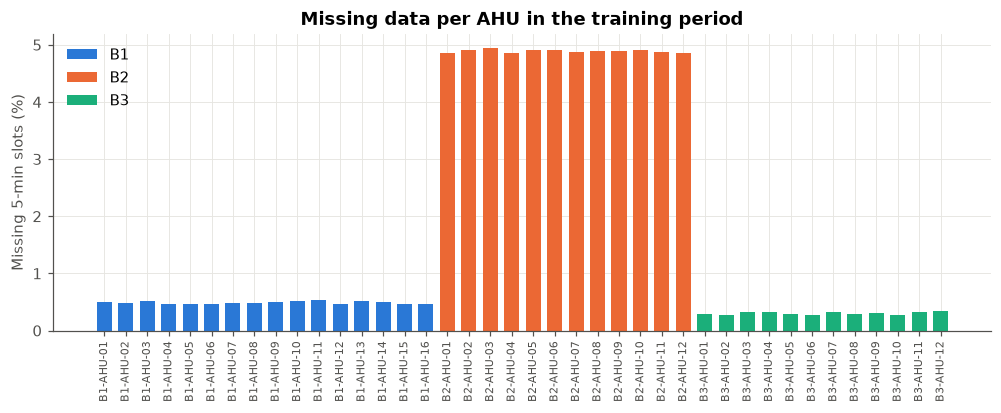

In [12]:
# Missing data per machine in train, one bar per machine, coloured by building
fig, ax = plt.subplots(figsize=(11, 3.5))
bar_colors = [BUILDING_COLORS[ahu[:2]] for ahu in cov_train.index]
ax.bar(cov_train.index, cov_train["missing_pct"], color=bar_colors, width=0.7)

# Legend: one entry per building
for building, color in BUILDING_COLORS.items():
    ax.bar(0, 0, color=color, label=building)
ax.legend(loc="upper left")

ax.set_ylabel("Missing 5-min slots (%)")
ax.set_title("Missing data per AHU in the training period")
ax.tick_params(axis="x", rotation=90, labelsize=7)
save_fig(fig, "01_missing_per_ahu")
plt.show()

**Obs:**
- Train has 2.05M rows (1 Jan to 30 Jun 2025) and test 712k rows (1 Jul to 31 Aug 2025). Same columns, all 40 machines in both.
- **Each building has its own problem in train, and it affects all its machines in the same way:**
  - **B1 (office):** all 16 machines have duplicate rows, up to 96 per machine (8 hours). Missing slots are low (0.5%). Section 3.2 explains where these 8 hours come from.
  - **B2 (hospital):** no duplicates at all, but every machine misses about **4.9% of the period (around 9 days)**.
  - **B3 (mall):** all 12 machines have duplicates, up to 288 per machine (exactly one full day). Missing slots are low (0.3%).
- When every machine of a building has the same problem, it is not a broken sensor. It points to how the data was exported or stored by each building's BMS.
- **Test is clean:** no duplicates and about 0.3% missing slots in every building.
- I look at when the gaps and duplicates happen, and whether duplicate rows have the same values, in `02_data_quality`.

**Ask the operator.** The BMS (building management system) is the central computer of each building: it controls the machines and saves the sensor readings every 5 minutes. Someone exported that data to files for us. Both problems look like they come from there, not from the machines.

1. **"Was the B2 BMS or its network down for some days in the first half of 2025?"**
   - *What I saw:* all 12 hospital machines miss about 9 days, all of them at the same time.
   - *What I think:* one broken sensor would affect one machine, not twelve. So the hospital BMS probably stopped saving data (crash, network cut, maintenance).
   - *Why it matters:* if so, those days have no data at all. The machines were running, but nobody wrote it down. I treat them as gaps and don't invent values.
2. **"How was the mall data exported? Was it joined from several files?"**
   - *What I saw:* every mall machine has repeated rows, up to a full day (288 rows).
   - *What I think:* a full repeated day is the typical trace of joining files that overlap, for example one export "1 to 15 March" and another "15 to 31 March", so 15 March appears twice.
   - *Why it matters:* if the two copies are identical, I just drop one and lose nothing. If they have different values, I need to know which one is right (for example, a corrected reading).

I check part of this myself in `02_data_quality`: whether the repeated rows are identical and on which dates they fall, and whether the B2 gap is one block of days or many small ones.

## 3. When do the machines run?

**Why it matters:** only rows with the fan on are scored, and when the fan is off the sensor values mean little (no air moves). So I need to know when each building really runs, and compare it with the declared schedules from the ID cards.

**How:** `fan_status` is 1 (on) or 0 (off). The average of a 0/1 column is the share of rows where it is 1. So `fan_status.mean()` = share of time the machine is on.

In [13]:
# Share of time with the fan on, overall and per building, in %
print(f"All rows: {train['fan_status'].mean():.1%}")
fan_on_share = train.groupby("building")["fan_status"].mean()
fan_on_share.map("{:.1%}".format)

All rows: 64.3%


building
B1     43.2%
B2    100.0%
B3     58.3%
Name: fan_status, dtype: str

**How to read it:** B3 = 58.3% means the mall machines are on 58.3% of the time. A day has 24 hours, so that is about 14 hours a day (09:00 to 23:00). B2 = 100% means always on. B1 = 43.2% is lower because the office is closed at night and at weekends.

Now **hour by hour**, to see the daily schedule. **How:** add the hour of the day and a weekend flag to each row, then compute the share of fan on for each building, weekday/weekend and hour.

In [14]:
# Hour of the day (0-23) and weekend flag for every row
train["hour"] = train["timestamp"].dt.hour
train["weekend"] = train["timestamp"].dt.day_of_week >= 5  # Monday = 0 ... Saturday = 5, Sunday = 6

# Leave out the two 24/7 machines of the office (B1), so the B1 profile shows the office schedule
office_24_7 = meta.loc[(meta["building"] == "B1") & (meta["operating_hours"] == "24/7"), "ahu_id"]
scheduled = train[~train["ahu_id"].isin(office_24_7)]

# Share of fan on for each (building, weekend, hour).
# Example: profile["B1", False, 9] = B1 on weekdays at 9:00
profile = scheduled.groupby(["building", "weekend", "hour"])["fan_status"].mean()

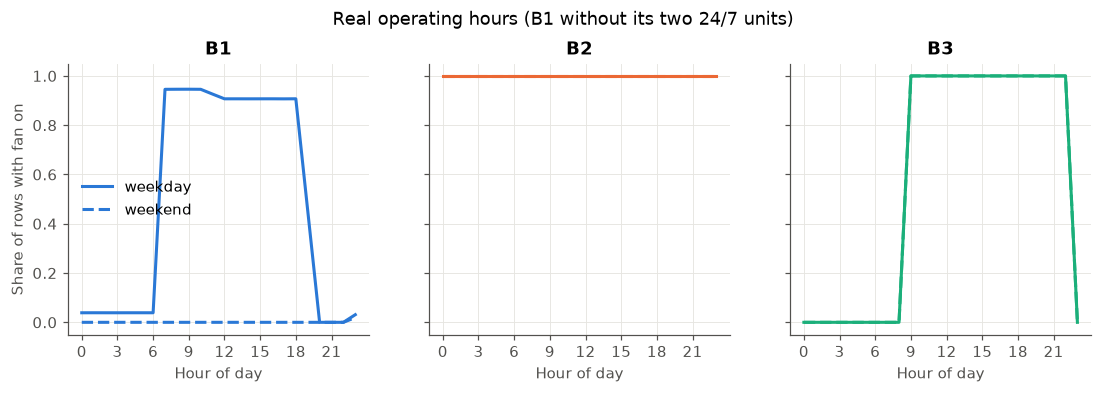

In [15]:
# One small chart per building: weekday (solid line) vs weekend (dashed line)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, building in zip(axes, ["B1", "B2", "B3"], strict=True):
    for weekend, style in [(False, "-"), (True, "--")]:
        label = "weekend" if weekend else "weekday"
        ax.plot(profile[building, weekend], style, color=BUILDING_COLORS[building], label=label)
    ax.set_title(building)
    ax.set_xlabel("Hour of day")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("Share of rows with fan on")
axes[0].legend()
fig.suptitle("Real operating hours (B1 without its two 24/7 units)", y=1.03)
save_fig(fig, "01_operating_hours")
plt.show()

**How to read the chart:** each line goes from 0 (all machines off at that hour) to 1 (all on). For example, B1 on weekdays at 9:00 is about 0.95: on 95% of the weekdays the office machines were on at 9:00.

**Obs:**
- **B3 (mall)** jumps from 0 to 1 at 09:00 and back to 0 at 23:00, every day, weekends included. It matches the declared hours exactly.
- **B2 (hospital)** is a flat line at 1: always on, as declared. The two 24/7 machines in B1 too.
- **B1 (office)** runs on weekdays from 07:00 to 19:30 and is off at weekends, as declared. But three details don't fit a perfect office schedule:
  - at 9:00 the line is at 0.95, not 1. On some weekdays the office didn't run at all;
  - between midnight and 07:00 it is at 0.04, not 0. On some weekdays the office ran at night;
  - from 11:00 it drops from 0.95 to 0.91. On some weekdays the office stopped before noon.

I look at each one below.

### 3.1 Weekdays with the office closed

**How:** for each weekday, the share of B1 rows with the fan on. A day close to 0 means the office didn't run at all that day.

In [16]:
office_weekdays = scheduled[(scheduled["building"] == "B1") & ~scheduled["weekend"]]
daily_fan_on = office_weekdays.groupby(office_weekdays["timestamp"].dt.date)["fan_status"].mean()

# Days with almost no machine running, with the name of the day
closed = daily_fan_on[daily_fan_on < 0.05].to_frame("fan_on_share")
closed["day"] = pd.to_datetime(closed.index).day_name()
closed

,fan_on_share,day
timestamp,,
2025-01-01,0.0,Wednesday
2025-01-29,0.0,Wednesday
2025-01-30,0.0,Thursday
2025-03-31,0.0,Monday
2025-04-18,0.0,Friday
2025-05-01,0.0,Thursday
2025-05-12,0.0,Monday


**Obs:**
- 7 weekdays with the office closed: 1 Jan, 29 and 30 Jan, 31 Mar, 18 Apr, 1 May and 12 May. These are the **2025 public holidays in Singapore** (New Year, Chinese New Year, Hari Raya Puasa, Good Friday, Labour Day, Vesak Day). With UTC+8 time, the buildings are very likely in Singapore.
- This explains the 0.95 at 9:00: 7 holidays out of about 129 weekdays is about 5%.

**Decision:** I use the Singapore holiday calendar when I need to know if B1 should be running. In the test period (Jul–Aug) the only holiday is National Day on 9 Aug, which is a Saturday.

### 3.2 Nights with the office running

**How:** for each date, the share of B1 rows with the fan on outside office hours (before 07:00 or from 20:00). The office should be off then, so any value above 0 is strange.

In [17]:
office = scheduled[scheduled["building"] == "B1"]
outside_hours = office[(office["hour"] < 7) | (office["hour"] >= 20)]
night_fan_on = outside_hours.groupby(outside_hours["timestamp"].dt.date)["fan_status"].mean()

# Dates where the office ran outside its hours
odd_nights = night_fan_on[night_fan_on > 0].to_frame("fan_on_share_outside_hours")
odd_nights["day"] = pd.to_datetime(odd_nights.index).day_name()
odd_nights.round(2)

,fan_on_share_outside_hours,day
timestamp,,
2025-06-01,0.07,Sunday
2025-06-02,0.73,Monday
2025-06-03,0.73,Tuesday
2025-06-04,0.73,Wednesday
2025-06-05,0.73,Thursday
2025-06-06,0.64,Friday


All the strange nights are in **one week: 1 to 6 June**. I look at one of those days hour by hour, next to a normal Monday a week later.

In [18]:
# Share of B1 machines on at each hour, for a strange Monday and a normal Monday
odd_day = office[office["timestamp"].dt.date == pd.Timestamp("2025-06-02").date()]
normal_day = office[office["timestamp"].dt.date == pd.Timestamp("2025-06-09").date()]
pd.DataFrame(
    {
        "Mon 2 Jun": odd_day.groupby("hour")["fan_status"].mean(),
        "Mon 9 Jun": normal_day.groupby("hour")["fan_status"].mean(),
    }
).T.round(1)

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Mon 2 Jun,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
Mon 9 Jun,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.5,0.0,0.0,0.0,0.0


In [19]:
# Same two days, now the outdoor temperature: on a normal day it peaks in the early afternoon
pd.DataFrame(
    {
        "Mon 2 Jun": odd_day.groupby("hour")["oat_c"].mean(),
        "Mon 9 Jun": normal_day.groupby("hour")["oat_c"].mean(),
    }
).T.astype(float).round(1)  # astype(float): the sensors are stored as float32, which prints badly

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Mon 2 Jun,27.2,28.1,29.2,29.9,30.3,31.0,31.2,31.2,30.5,29.6,29.3,28.8,27.8,27.0,26.4,25.3,24.6,24.3,24.7,25.0,25.2,25.4,26.0,26.8
Mon 9 Jun,25.2,25.4,25.1,24.8,24.8,25.3,26.1,27.0,27.6,28.8,29.4,29.9,30.5,30.9,30.9,28.7,26.2,27.2,27.5,27.4,27.1,27.1,26.5,25.4


**Obs: one office week was saved with the clock 8 hours early.**

- **What I saw:** on Monday 2 June the office runs from 23:00 to 11:30 instead of 07:00 to 19:30, and the outside temperature peaks at 07:00 instead of 14:00. Everything is 8 hours early.
- **What it means:** from 2 to 8 June the office data was saved in UTC instead of Singapore time (UTC+8). The machines worked normally; only the time written in the diary is wrong. The mall is not affected.
- **What it explains:** the odd night hours in the chart above, the 96 duplicate rows per office machine on 1 June (the start of the shifted week lands on top of real hours), and an 8-hour hole on 8 June (where it ends).
- **How I fix it (in `02_data_quality`):** move that week 8 hours later, back to local time. Then I check that the duplicates and the hole are gone and the office runs 07:00–19:30 again.

**Ask the operator:** "Was the office BMS changed or restarted around 1 June 2025?" If the clock or time zone was changed, it confirms the fix.

## 4. The repair reports: which faults, where and for how long?

**How:** count the events per fault type and building, measure how long they last, and draw them on a timeline.

Plain names for the faults (more in `docs/03 - AHU physics and faults.md`):

| Label | Plain name | What breaks |
|---|---|---|
| `chw_valve_stuck` | stuck tap | the cold water valve doesn't follow its command |
| `oa_damper_stuck` | stuck flap | the outdoor-air flap is stuck nearly closed |
| `sat_sensor_bias` | lying thermometer | the supply air sensor reads too high or too low |
| `low_coil_capacity` | weak radiator | the coil cools much less than usual |

In [20]:
# Length of each event in days (end - start), and its building
labels["days"] = (labels["end"] - labels["start"]) / pd.Timedelta("1D")
labels = add_building(labels)

# One row per fault type: how many events, in how many machines, how long they last
summary = (
    labels.groupby("fault_type")
    .agg(
        events=("ahu_id", "size"),
        machines=("ahu_id", "nunique"),
        days_min=("days", "min"),
        days_median=("days", "median"),
        days_max=("days", "max"),
    )
    .round(1)
)
summary.insert(0, "plain_name", summary.index.map(FAULT_NAMES))

# Add how many events of each type happened in each building
summary.join(pd.crosstab(labels["fault_type"], labels["building"]))

,plain_name,events,machines,days_min,days_median,days_max,B1,B2,B3
fault_type,,,,,,,,,
chw_valve_stuck,stuck tap,8,8,2.3,5.6,8.1,2,2,4
low_coil_capacity,weak radiator,7,6,3.1,4.3,6.8,3,3,1
oa_damper_stuck,stuck flap,7,6,3.2,5.6,11.2,4,1,2
sat_sensor_bias,lying thermometer,6,6,7.1,10.3,14.5,1,0,5


**How to read it:** one row per fault type.
- `events`: number of repair reports. `machines`: in how many different machines. If `machines` < `events`, some machine had that fault twice.
- `days_min`, `days_median`, `days_max`: shortest, typical and longest event. The median is the middle value: half the events are shorter, half are longer.
- `B1`, `B2`, `B3`: number of events in each building.

Example: stuck tap = 8 events in 8 machines, typically 5.6 days long, 4 of them in the mall.

In [21]:
# Machines with more than one event
print("Machines with at least one event:", labels["ahu_id"].nunique(), "of", len(meta))
events_per_machine = labels["ahu_id"].value_counts()
events_per_machine[events_per_machine > 1]

Machines with at least one event: 21 of 40


ahu_id
B3-AHU-02    3
B2-AHU-04    2
B1-AHU-01    2
B1-AHU-04    2
B3-AHU-06    2
B3-AHU-05    2
Name: count, dtype: int64

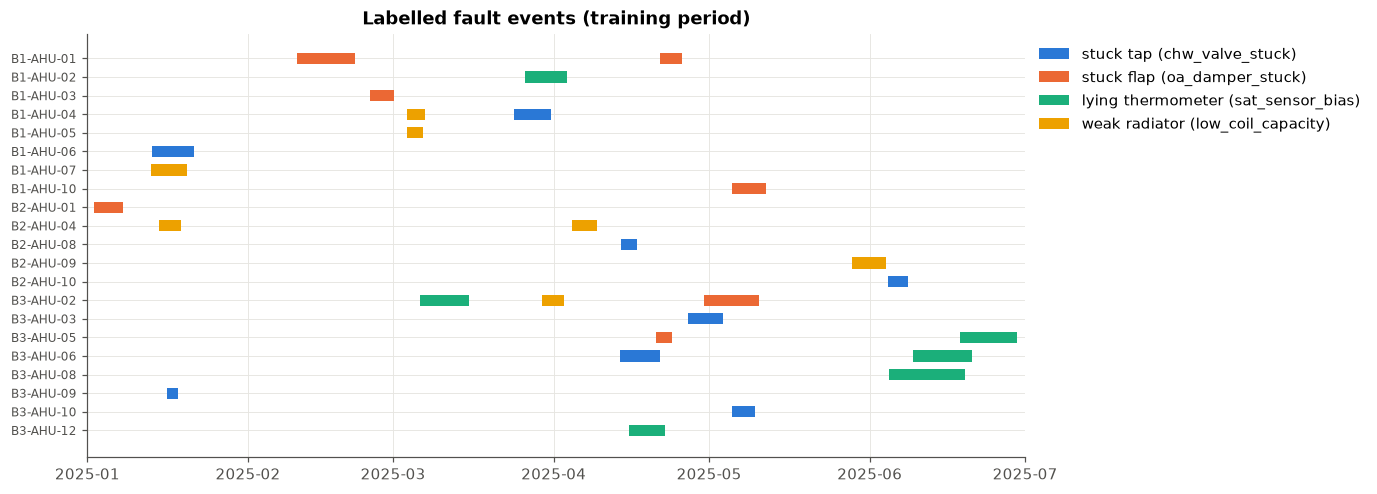

In [22]:
# Timeline: one line per machine with events, one bar per event, coloured by fault type
fig, ax = plt.subplots(figsize=(11, 5))
ahus = sorted(labels["ahu_id"].unique(), reverse=True)
for event in labels.itertuples():
    ax.barh(
        ahus.index(event.ahu_id),  # row of the machine
        event.end - event.start,  # bar length = event duration
        left=event.start,
        height=0.6,
        color=FAULT_COLORS[event.fault_type],
    )
ax.set_yticks(range(len(ahus)), ahus, fontsize=8)
ax.set_xlim(pd.Timestamp("2025-01-01"), pd.Timestamp("2025-07-01"))

# Legend: one entry per fault type, with its plain name
for fault in FAULT_TYPES:
    ax.barh(
        0,
        pd.Timedelta(0),
        left=pd.Timestamp("2025-01-01"),
        color=FAULT_COLORS[fault],
        label=f"{FAULT_NAMES[fault]} ({fault})",
    )
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("Labelled fault events (training period)")
save_fig(fig, "01_label_timeline")
plt.show()

**How to read the chart:** each line is one machine that had at least one fault. Each bar is one repair report: it starts when the fault began and ends when it was repaired. The colour is the fault type.

**Obs:**
- Only **28 events**: 8 stuck tap, 7 weak radiator, 7 stuck flap and 6 lying thermometer. Very few examples per fault, so a model can't learn the faults from the labels alone. The physics will have to do part of the work.
- Only 21 of the 40 machines have an event. Events never overlap on the same machine, and they are spread over the six months.
- Events last 2 to 15 days. **The lying thermometer lasts the longest (median 10 days).** It makes sense: the controller trusts the sensor, so nothing looks wrong and the fault takes longer to be found.
- The lying thermometer is labelled 5 times in the mall and never in the hospital. The hospital is the only building with an airflow sensor, which would help to catch a lying thermometer. So I can't test that idea on labelled data.
- B3-AHU-02 had three different faults in four months (lying thermometer, weak radiator, stuck flap). It could be a machine in bad shape, or the faults are related.

**Ask the operator: "How do your technicians fill in the start time of a fault in the work order?"**
- *What I saw:* every event has an exact start time, to the minute.
- *What I think:* the real start is usually unknown. The technician estimates it after finding the fault (for example, from the first complaint).
- *Why it matters:* the score rewards detecting a fault soon after it starts. If the start times are rough guesses, my measured detection delay will be rough too, and the model may learn from rows that were still healthy.

## 5. Painting the diary with the repair reports

Each diary row gets the fault name if it falls inside a repair report, or `normal` if not (`label_rows()` in `src/ahu_fdd/data.py`, explained in `docs/01 - Data.md`). **How:** paint the train diary, then look only at the rows that are scored (fan on).

In [23]:
# Give every train row its label: a fault type or "normal"
train["label"] = label_rows(train, labels)
fan_on = train[train["fan_status"] == 1]  # only these rows are scored

# Share of scored rows per label
fan_on["label"].value_counts(normalize=True).map("{:.2%}".format)

label
normal               97.64%
sat_sensor_bias       0.74%
oa_damper_stuck       0.55%
chw_valve_stuck       0.54%
low_coil_capacity     0.53%
Name: proportion, dtype: str

**How to read it:** `value_counts(normalize=True)` gives the share of rows for each label. For example, `sat_sensor_bias` 0.74% means that 0.74% of the scored rows belong to a lying thermometer event.

In [24]:
# Hours with the fan on inside each event (fan_on_hours_per_event is in src/ahu_fdd/eda.py)
labels["fan_on_hours"] = fan_on_hours_per_event(train, labels)
labels.groupby("fault_type")["fan_on_hours"].agg(["min", "median", "max"]).round(0)

,min,median,max
fault_type,,,
chw_valve_stuck,32.0,75.0,104.0
low_coil_capacity,40.0,62.0,157.0
oa_damper_stuck,46.0,57.0,144.0
sat_sensor_bias,64.0,142.0,200.0


**How to read it:** for each fault type, the shortest, typical and longest number of hours with the fan on during an event. An event can last 2 days, but in the mall the fan is off at night, so only part of that time is scored.

**Obs:**
- With the fan on, **97.6% of the rows are normal and 2.4% are faults** (about 0.5% per fault type). It's a very imbalanced problem: a model that always says "normal" would be right 97.6% of the time and still be useless, because it would never find a fault. So accuracy is not a good metric here. This matches how the scoring works: by events and false alarms, not by rows.
- Every event has at least 32 hours with the fan on (the shortest is a stuck tap in B3-AHU-09, 2.3 days long), so each event gives enough rows to see its signature.

## Summary

- 40 machines in three buildings (office, hospital, mall), very different in size and in sensors. The mall has no extra sensors.
- In train each building has its own data problem: duplicates in every office and mall machine, about 5% missing slots in every hospital machine. Test is clean.
- Real schedules match the declared ones. The office follows the Singapore 2025 public holidays, so the buildings are very likely in Singapore.
- **One week of office data (2–8 June) is stamped 8 hours early (UTC instead of local time).** It explains the office duplicates and the odd night hours. I fix it in `02_data_quality`.
- Only 28 labelled events in 21 machines, 6–8 per fault type, lasting 2–15 days. Faults are 2.4% of the scored rows.
- Next: `02_data_quality`.